In [3]:
#Environment and project paths
from pathlib import Path
import os, sys, random, json, time, copy, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.transforms import functional as TF

import os


In [4]:

from google.colab import drive
drive.mount('/content/drive')

%cd /content

# Remove the previous incomplete clone, if any
!rm -rf /content/repo

# Clone the specified branch
!git clone --branch vision-transformer --single-branch https://github.com/Teamoreteateo/CS3244-DeepWeeds.git /content/repo


Mounted at /content/drive
/content
Cloning into '/content/repo'...
remote: Enumerating objects: 106, done.
remote: Counting objects: 100% (106/106), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 106 (delta 51), reused 61 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (106/106), 7.54 MiB | 9.32 MiB/s, done.
Resolving deltas: 100% (51/51), done.


In [7]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")


Device: cuda
GPU Name: NVIDIA L4


In [8]:

%cd /content/repo

!pip install -q scikit-image

!git log --oneline -2

# Copy your dataset from Google Drive
!mkdir -p data
!cp /content/drive/MyDrive/CS3244-DeepWeeds/data/labels.csv data/labels.csv
!rsync -ah --info=progress2 \
  /content/drive/MyDrive/CS3244-DeepWeeds/data/images/ \
  /content/repo/data/images/
# Verify that the files exist
!ls -l data/labels.csv
!ls data/images | wc -l


/content/repo
97ed393 (HEAD -> vision-transformer, origin/vision-transformer) Add resnet18 scratch result
20116ba Repair results.csv; guard against missing trailing newline in log_result
        492.31M 100%   36.93kB/s    3:36:56 (xfr#17518, to-chk=0/17520)
-rw------- 1 root root 598898 Oct 19 14:44 data/labels.csv
17519


In [9]:

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/CS3244-DeepWeeds/checkpoints"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Checkpoints will be stored in:", CHECKPOINT_DIR)
#no checkpoints for now only if needed"

Checkpoints will be stored in: /content/drive/MyDrive/CS3244-DeepWeeds/checkpoints


In [10]:

REPO_ROOT = Path.cwd().parent  # Current directory is notebooks
sys.path.insert(0, str(REPO_ROOT))


In [11]:


SEED = 42
VAL_FOLD = 0
SPLIT = "grouped"
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0
EPOCHS_SCRATCH = 15
EPOCHS_HF = 5
USE_WEIGHTED_SAMPLING = True
USE_CUTMIX = False
CUTMIX_PROBABILITY = 0.5
LEARNING_RATE_SCRATCH = 3e-4
LEARNING_RATE_HF = 2e-5
WEIGHT_DECAY = 1e-4

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "splits" / "folds.csv").exists() and (p / "data" / "images").is_dir():
            return p
    for p in candidates:
        if (p / "splits" / "folds.csv").exists():
            return p
    raise FileNotFoundError(
        "Could not locate splits/folds.csv. Run this notebook from the project/repository "
        "or set PROJECT_ROOT manually."
    )

PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
sys.path.insert(0, str(SRC_DIR))
IMG_DIR = PROJECT_ROOT / "data" / "images"
FOLDS_PATH = PROJECT_ROOT / "splits" / "folds.csv"
RESULTS_PATH = PROJECT_ROOT / "results.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "vit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", PROJECT_ROOT)
print("Image directory:", IMG_DIR, "| exists:", IMG_DIR.is_dir())
print("Fold manifest:", FOLDS_PATH, "| exists:", FOLDS_PATH.exists())
print("Device:", device)
print("PyTorch:", torch.__version__)
assert SPLIT == "grouped" and VAL_FOLD == 0, "Keep fold=0, split='grouped' for comparable runs."
assert IMG_DIR.is_dir(), f"Missing {IMG_DIR}. Download/unzip DeepWeeds images as instructed."
assert FOLDS_PATH.exists(), f"Missing {FOLDS_PATH}. Pull the committed split manifest first."

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()


Project root: /content/repo
Image directory: /content/repo/data/images | exists: True
Fold manifest: /content/repo/splits/folds.csv | exists: True
Device: cuda
PyTorch: 2.11.0+cu130


## 2. Load the committed split and verify leakage


In [12]:
df = pd.read_csv(FOLDS_PATH, dtype={"session": str, "date": str})
required = {"Filename", "Species", "is_test", "session", "fold_grouped"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"folds.csv missing required columns: {sorted(missing)}")

if df["is_test"].dtype != bool:
    df["is_test"] = df["is_test"].astype(str).str.lower().map({"true": True, "false": False})
if df["is_test"].isna().any():
    raise ValueError("is_test contains missing/unparseable values")

non_test = df.loc[~df["is_test"]].copy()
fold_col = f"fold_{SPLIT}"
if non_test[fold_col].isna().any() or (non_test[fold_col] < 0).any():
    raise ValueError(f"Invalid fold assignments in {fold_col}")

train_df = non_test.loc[non_test[fold_col] != VAL_FOLD].copy().reset_index(drop=True)
val_df = non_test.loc[non_test[fold_col] == VAL_FOLD].copy().reset_index(drop=True)
classes = sorted(df["Species"].dropna().unique().tolist())
class_to_idx = {name: i for i, name in enumerate(classes)}
NUM_CLASSES = len(classes)

assert NUM_CLASSES == 9, f"Expected 9 DeepWeeds classes, found {NUM_CLASSES}"
assert len(train_df) and len(val_df)
assert set(train_df["Filename"]).isdisjoint(val_df["Filename"])
assert set(train_df["Filename"]).isdisjoint(set(df.loc[df["is_test"], "Filename"]))
assert set(val_df["Filename"]).isdisjoint(set(df.loc[df["is_test"], "Filename"]))
assert set(train_df["session"]).isdisjoint(val_df["session"]), "Grouped train/validation session leakage"
assert set(non_test["session"]).isdisjoint(set(df.loc[df["is_test"], "session"])), "Test session leakage"

print(f"Split: {SPLIT}; validation fold: {VAL_FOLD}")
print(f"Train: {len(train_df):,}; validation: {len(val_df):,}; held-out test excluded: {int(df['is_test'].sum()):,}")
print("Classes:", classes)
display(pd.DataFrame({
    "train": train_df["Species"].value_counts().reindex(classes, fill_value=0),
    "validation": val_df["Species"].value_counts().reindex(classes, fill_value=0),
}))


Split: grouped; validation fold: 0
Train: 10,820; validation: 2,454; held-out test excluded: 4,235
Classes: ['Chinee apple', 'Lantana', 'Negative', 'Parkinsonia', 'Parthenium', 'Prickly acacia', 'Rubber vine', 'Siam weed', 'Snake weed']


,train,validation
Species,,
Chinee apple,509,103
Lantana,681,184
Negative,5625,1393
Parkinsonia,809,222
Parthenium,648,177
Prickly acacia,581,87
Rubber vine,785,135
Siam weed,605,49
Snake weed,577,104


## 3. Image transforms and datasets

Training augmentation follows the  `02_splits_augmentation.ipynb` / `src/data_pipeline.py` Both models use ImageNet normalization so the pretrained model receives its expected input scale.

In [14]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

class RandomRotate90:
    def __call__(self, image):
        return TF.rotate(image, random.choice((0, 90, 180, 270)))

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(IMAGE_SIZE),
    RandomRotate90(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=(0.4, 1.3), contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class DeepWeedsDataset(Dataset):
    def __init__(self, frame, img_dir, transform, class_to_idx):
        self.df = frame.reset_index(drop=True).copy()
        self.img_dir = Path(img_dir)
        self.transform = transform
        self.class_to_idx = class_to_idx
    def __len__(self):
        return len(self.df)
    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_path = self.img_dir / row["Filename"]
        with Image.open(image_path) as im:
            image = im.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, self.class_to_idx[row["Species"]]

train_dataset = DeepWeedsDataset(train_df, IMG_DIR, train_transform, class_to_idx)
val_dataset = DeepWeedsDataset(val_df, IMG_DIR, eval_transform, class_to_idx)

train_sampler = None
if USE_WEIGHTED_SAMPLING:
    counts = train_df["Species"].value_counts()
    weights = (1.0 / train_df["Species"].map(counts)).to_numpy(dtype=np.float64)
    train_sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double),
                                          num_samples=len(train_dataset), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=(train_sampler is None), sampler=train_sampler,
                          num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

xb, yb = next(iter(train_loader))
print("Image batch:", tuple(xb.shape), "| labels:", tuple(yb.shape))
assert xb.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)


Image batch: (16, 3, 224, 224) | labels: (16,)


## 4. Metrics and training utilities

We report accuracy, macro-F1, macro precision/recall, weighted-F1, and validation loss.

In [15]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix

import sys
sys.path.append("..")

try:
    from src.metrics import log_result
    HAS_PROJECT_LOGGER = True
except Exception as exc:
    print("Could not import src/metrics.py log_result:", repr(exc))
    HAS_PROJECT_LOGGER = False

def evaluate_model(model, loader, criterion):
    model.eval()
    total_loss, total_n = 0.0, 0
    y_true, y_pred = [], []
    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            n = labels.size(0)
            total_loss += loss.item() * n
            total_n += n
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    return {
        "loss": total_loss / max(total_n, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "y_true": y_true,
        "y_pred": y_pred,
    }


def train_model(
    model, train_loader, val_loader, epochs, lr, weight_decay, run_name,
    use_cutmix=False, cutmix_probability=0.5,
    resume_from=None,
):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                  lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = []
    best_f1 = -1.0
    best_state = None
    cutmix_fn = None
    if use_cutmix:
        from torchvision.transforms import v2
        cutmix_fn = v2.CutMix(num_classes=NUM_CLASSES, alpha=1.0)

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, seen, correct = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            if cutmix_fn is not None and torch.rand(()).item() < cutmix_probability:
                images, mixed_labels = cutmix_fn(images, labels)
                logits = model(images)
                loss = -(mixed_labels * torch.log_softmax(logits, dim=1)).sum(dim=1).mean()
            else:
                logits = model(images)
                loss = criterion(logits, labels)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            n = labels.size(0)
            running_loss += loss.item() * n
            seen += n
            correct += (logits.argmax(dim=1) == labels).sum().item()
        scheduler.step()
        val_metrics = evaluate_model(model, val_loader, criterion)
        row = {
            "epoch": epoch,
            "train_loss": running_loss / max(seen, 1),
            "train_accuracy": correct / max(seen, 1),
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "val_macro_precision": val_metrics["macro_precision"],
            "val_macro_recall": val_metrics["macro_recall"],
            "val_weighted_f1": val_metrics["weighted_f1"],
            "lr": optimizer.param_groups[0]["lr"],
        }
        history.append(row)
        print(f"{run_name} | epoch {epoch:02d}/{epochs} | "
              f"train loss {row['train_loss']:.4f} acc {row['train_accuracy']:.4f} | "
              f"val loss {row['val_loss']:.4f} acc {row['val_accuracy']:.4f} "
              f"macro-F1 {row['val_macro_f1']:.4f} weighted-F1 {row['val_weighted_f1']:.4f}")
        if row["val_macro_f1"] > best_f1:
            best_f1 = row["val_macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            torch.save({
                "model_state_dict": best_state,
                "run_name": run_name,
                "best_epoch": epoch,
                "best_val_macro_f1": best_f1,
                "classes": classes,
                "split": SPLIT,
                "val_fold": VAL_FOLD,
                "seed": SEED,
            }, OUTPUT_DIR / f"{run_name}_best.pt")
        scheduler.step if False else None

    if best_state is not None:
        model.load_state_dict(best_state)
    best_metrics = evaluate_model(model, val_loader, criterion)
    history_df = pd.DataFrame(history)
    history_df.to_csv(OUTPUT_DIR / f"{run_name}_history.csv", index=False)
    result_summary = {k: v for k, v in best_metrics.items() if k not in ("y_true", "y_pred")}
    result_summary["best_val_macro_f1"] = best_f1
    result_summary["best_epoch"] = int(history_df.loc[history_df["val_macro_f1"].idxmax(), "epoch"])
    result_summary["n_train"] = len(train_dataset)
    result_summary["n_validation"] = len(val_dataset)
    result_summary["split"] = SPLIT
    result_summary["val_fold"] = VAL_FOLD
    result_summary["seed"] = SEED
    if HAS_PROJECT_LOGGER:
        try:
            # Project convention: log_result(model_name, split_scheme, params, summary)
            log_result(run_name, SPLIT, {
                "val_fold": VAL_FOLD, "seed": SEED, "epochs": epochs,
                "batch_size": BATCH_SIZE, "lr": lr, "weight_decay": weight_decay,
                "weighted_sampling": USE_WEIGHTED_SAMPLING, "cutmix": use_cutmix,
            }, result_summary)
            print("Logged through metrics.log_result to project results.csv.")
        except Exception as exc:
            print("Project log_result call failed; see note below:", repr(exc))
            print("Metrics are saved in:", OUTPUT_DIR)
    else:
        print("Project logger unavailable; metrics are saved in outputs/vit, not appended to results.csv.")
    return model, history_df, result_summary


## 5. Model A — Vision Transformer trained from scratch

This is a small ViT built from scratch specifically for this dataset: 16×16 patches (196 patches at 224×224), learned class token and positional embeddings, 6 Transformer encoder layers, 8 attention heads, and a 9-class output head. No pretrained weights are loaded.

In [16]:
class ScratchViT(nn.Module):
    def __init__(self, num_classes, image_size=224, patch_size=16, embed_dim=384,
                 depth=6, num_heads=6, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        assert image_size % patch_size == 0
        self.patch_size = patch_size
        n_patches = (image_size // patch_size) ** 2
        self.patch_embed = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=depth, norm=nn.LayerNorm(embed_dim))
        self.head = nn.Sequential(nn.LayerNorm(embed_dim), nn.Dropout(dropout),
                                  nn.Linear(embed_dim, num_classes))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.kaiming_normal_(self.patch_embed.weight, mode="fan_out", nonlinearity="relu")
        if self.patch_embed.bias is not None:
            nn.init.zeros_(self.patch_embed.bias)
    def forward(self, x):
        x = self.patch_embed(x)                 # B, D, H/patch, W/patch
        x = x.flatten(2).transpose(1, 2)        # B, N, D
        cls = self.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat((cls, x), dim=1) + self.pos_embed
        x = self.pos_drop(x)
        x = self.encoder(x)
        return self.head(x[:, 0])

scratch_model = ScratchViT(NUM_CLASSES, image_size=IMAGE_SIZE, patch_size=16,
                           embed_dim=384, depth=6, num_heads=6, dropout=0.1)
print(scratch_model)
print(f"Trainable parameters: {sum(p.numel() for p in scratch_model.parameters() if p.requires_grad):,}")


ScratchViT(
  (patch_embed): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
  (pos_drop): Dropout(p=0.1, inplace=False)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=384, out_features=384, bias=True)
        )
        (linear1): Linear(in_features=384, out_features=1536, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=1536, out_features=384, bias=True)
        (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
    (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
  )
  (head): Sequential(
    (0): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
    (1): Dropou

/tmp/ipykernel_1334/2938882161.py:16: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=depth, norm=nn.LayerNorm(embed_dim))


In [17]:
scratch_model, scratch_history, scratch_summary = train_model(
    scratch_model, train_loader, val_loader,
    epochs=EPOCHS_SCRATCH,
    lr=LEARNING_RATE_SCRATCH,
    weight_decay=WEIGHT_DECAY,
    run_name="vit_scratch",
    use_cutmix=USE_CUTMIX,
    cutmix_probability=CUTMIX_PROBABILITY,
)
display(scratch_history.tail())
print("Best validation summary:", scratch_summary)


vit_scratch | epoch 01/15 | train loss 2.1207 acc 0.1890 | val loss 1.9543 acc 0.2376 macro-F1 0.1831 weighted-F1 0.2395
vit_scratch | epoch 02/15 | train loss 1.8054 acc 0.3292 | val loss 1.7093 acc 0.2942 macro-F1 0.1991 weighted-F1 0.3424
vit_scratch | epoch 03/15 | train loss 1.6451 acc 0.3951 | val loss 1.8702 acc 0.2624 macro-F1 0.2312 weighted-F1 0.2662
vit_scratch | epoch 04/15 | train loss 1.5359 acc 0.4360 | val loss 1.5451 acc 0.4087 macro-F1 0.2792 weighted-F1 0.4339
vit_scratch | epoch 05/15 | train loss 1.4289 acc 0.4764 | val loss 1.7125 acc 0.3712 macro-F1 0.3175 weighted-F1 0.3865
vit_scratch | epoch 06/15 | train loss 1.3682 acc 0.4953 | val loss 1.7746 acc 0.3260 macro-F1 0.3017 weighted-F1 0.3496
vit_scratch | epoch 07/15 | train loss 1.2680 acc 0.5344 | val loss 1.7171 acc 0.3672 macro-F1 0.3184 weighted-F1 0.3905
vit_scratch | epoch 08/15 | train loss 1.1986 acc 0.5632 | val loss 1.6746 acc 0.3814 macro-F1 0.3244 weighted-F1 0.3937
vit_scratch | epoch 09/15 | trai

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1,val_macro_precision,val_macro_recall,val_weighted_f1,lr
10,11,1.029604,0.628373,1.855370,0.381826,0.358302,0.336489,0.514082,0.374695,0.000050
11,12,0.967506,0.652680,1.779861,0.390383,0.370210,0.357271,0.512754,0.392773,0.000029
12,13,0.920097,0.667560,1.748938,0.383048,0.358409,0.344919,0.514736,0.389659,0.000013
13,14,0.886524,0.680314,1.688082,0.415240,0.373372,0.352883,0.521135,0.425661,0.000003
14,15,0.872954,0.681885,1.642649,0.431133,0.382391,0.357717,0.523282,0.443645,0.000000


Best validation summary: {'loss': 1.6426490519040955, 'accuracy': 0.4311328443357783, 'macro_f1': 0.38239105621883174, 'macro_precision': 0.3577165382341078, 'macro_recall': 0.5232815644264471, 'weighted_f1': 0.44364496019435096, 'best_val_macro_f1': 0.38239105621883174, 'best_epoch': 15, 'n_train': 10820, 'n_validation': 2454, 'split': 'grouped', 'val_fold': 0, 'seed': 42}


In [18]:

from pathlib import Path
import torch

# Create the models directory
MODEL_DIR = Path("/content/repo/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the model weights and training information
save_path = MODEL_DIR / "vit_scratch.pth"

torch.save({
    "model_state_dict": scratch_model.state_dict(),
    "history": scratch_history.to_dict(),
    "summary": scratch_summary,
}, save_path)

print(f"Model saved to: {save_path}")
print(f"File size: {save_path.stat().st_size / (1024**2):.2f} MB")


Model saved to: /content/repo/models/vit_scratch.pth
File size: 42.08 MB


## 6. Model B — Hugging Face pretrained ViT-B/16 fine-tuned on DeepWeeds

Uses Hugging Face checkpoint `google/vit-base-patch16-224-in21k`. The pretrained backbone is initialized from the public checkpoint, and the classifier is replaced with a 9-class head. This is **fine-tuning**, not frozen embeddings: all backbone parameters are trainable. Internet access is needed the first time unless the checkpoint is already cached.

In [19]:
# Install once if needed in the notebook environment:
# %pip install -U transformers safetensors

try:
    from transformers import ViTForImageClassification
except ImportError as exc:
    raise ImportError("Install Hugging Face Transformers first: %pip install -U transformers safetensors") from exc

HF_CHECKPOINT = "google/vit-base-patch16-224-in21k"
id2label = {i: name for i, name in enumerate(classes)}
label2id = {name: i for i, name in enumerate(classes)}

hf_model = ViTForImageClassification.from_pretrained(
    HF_CHECKPOINT,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)
# Verify all parameters are trainable for a full fine-tuning comparison.
for parameter in hf_model.parameters():
    parameter.requires_grad = True

class HFViTClassifier(nn.Module):
    def __init__(self, hf_model):
        super().__init__()
        self.hf_model = hf_model
    def forward(self, pixel_values):
        return self.hf_model(pixel_values=pixel_values).logits

hf_classifier = HFViTClassifier(hf_model)
print("Checkpoint:", HF_CHECKPOINT)
print("Trainable parameters:", f"{sum(p.numel() for p in hf_classifier.parameters() if p.requires_grad):,}")


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Checkpoint: google/vit-base-patch16-224-in21k
Trainable parameters: 85,805,577


In [20]:
hf_classifier, hf_history, hf_summary = train_model(
    hf_classifier, train_loader, val_loader,
    epochs=EPOCHS_HF,
    lr=LEARNING_RATE_HF,
    weight_decay=WEIGHT_DECAY,
    run_name="vit_hf_vit_base_patch16_224_in21k_finetuned",
    use_cutmix=USE_CUTMIX,
    cutmix_probability=CUTMIX_PROBABILITY,
)
display(hf_history.tail())
print("Best validation summary:", hf_summary)


vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 01/5 | train loss 0.9830 acc 0.7730 | val loss 1.1750 acc 0.5844 macro-F1 0.5672 weighted-F1 0.6000
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 02/5 | train loss 0.3242 acc 0.9304 | val loss 0.8402 acc 0.7331 macro-F1 0.6914 weighted-F1 0.7478
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 03/5 | train loss 0.2019 acc 0.9560 | val loss 0.7694 acc 0.7734 macro-F1 0.7294 weighted-F1 0.7887
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 04/5 | train loss 0.1360 acc 0.9712 | val loss 0.7772 acc 0.7812 macro-F1 0.7283 weighted-F1 0.7998
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 05/5 | train loss 0.1144 acc 0.9782 | val loss 0.6324 acc 0.8150 macro-F1 0.7612 weighted-F1 0.8267
Project log_result call failed; see note below: TypeError('cannot unpack non-iterable float object')
Metrics are saved in: /content/repo/outputs/vit


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1,val_macro_precision,val_macro_recall,val_weighted_f1,lr
0,1,0.983025,0.773013,1.174956,0.584352,0.567167,0.559349,0.737481,0.599972,0.000018
1,2,0.324182,0.930407,0.840242,0.733089,0.691373,0.662356,0.826638,0.747795,0.000013
2,3,0.201940,0.956007,0.769366,0.773431,0.729384,0.682935,0.846553,0.788698,0.000007
3,4,0.135974,0.971165,0.777249,0.781174,0.728318,0.700409,0.847637,0.799833,0.000002
4,5,0.114446,0.978189,0.632407,0.814996,0.761216,0.739125,0.841652,0.826723,0.000000


Best validation summary: {'loss': 0.6324066468487937, 'accuracy': 0.8149959250203749, 'macro_f1': 0.7612160935700605, 'macro_precision': 0.7391254210272261, 'macro_recall': 0.8416520587234556, 'weighted_f1': 0.8267232223820521, 'best_val_macro_f1': 0.7612160935700605, 'best_epoch': 5, 'n_train': 10820, 'n_validation': 2454, 'split': 'grouped', 'val_fold': 0, 'seed': 42}


In [21]:

from pathlib import Path
import json
import shutil

# 1. Save to the Colab repository
MODEL_DIR = Path(
    "/content/repo/models/vit_hf_vit_base_patch16_224_in21k_finetuned"
)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the fine-tuned model and its configuration
hf_classifier.hf_model.save_pretrained(
    MODEL_DIR,
    safe_serialization=True,
)

# Save training history
hf_history.to_csv(MODEL_DIR / "training_history.csv", index=False)

# Save validation summary
with open(MODEL_DIR / "validation_summary.json", "w") as f:
    json.dump(hf_summary, f, indent=2, default=str)

# Save the class-label mappings
with open(MODEL_DIR / "class_labels.json", "w") as f:
    json.dump({
        "id2label": {str(k): v for k, v in id2label.items()},
        "label2id": label2id,
    }, f, indent=2)

print("Fine-tuned Hugging Face ViT saved to:", MODEL_DIR)
print("Saved files:")
for path in sorted(MODEL_DIR.iterdir()):
    print(f"  {path.name}: {path.stat().st_size / (1024**2):.2f} MB")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuned Hugging Face ViT saved to: /content/repo/models/vit_hf_vit_base_patch16_224_in21k_finetuned
Saved files:
  class_labels.json: 0.00 MB
  config.json: 0.00 MB
  model.safetensors: 327.34 MB
  training_history.csv: 0.00 MB
  validation_summary.json: 0.00 MB


## 7. Compare validation results

These are validation results only; use them for model selection and error analysis, not as a final unbiased test estimate. The `is_test=True` set remains untouched.

,loss,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,best_epoch
model,,,,,,,
Hugging Face ViT-B/16 fine-tuned,0.632407,0.814996,0.761216,0.739125,0.841652,0.826723,5
ViT from scratch,1.642649,0.431133,0.382391,0.357717,0.523282,0.443645,15


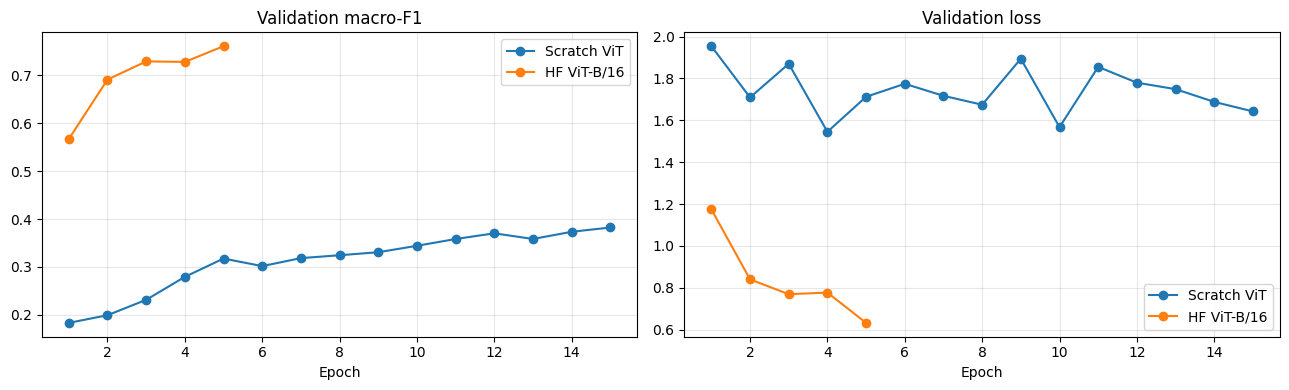

Saved outputs to: /content/repo/outputs/vit


In [22]:
comparison = pd.DataFrame([
    {"model": "ViT from scratch", **{k: v for k, v in scratch_summary.items()
                                    if k in ["loss", "accuracy", "macro_f1", "macro_precision",
                                             "macro_recall", "weighted_f1", "best_epoch"]}},
    {"model": "Hugging Face ViT-B/16 fine-tuned", **{k: v for k, v in hf_summary.items()
                                    if k in ["loss", "accuracy", "macro_f1", "macro_precision",
                                             "macro_recall", "weighted_f1", "best_epoch"]}},
]).set_index("model")
display(comparison.sort_values("macro_f1", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for hist, name in [(scratch_history, "Scratch ViT"), (hf_history, "HF ViT-B/16")]:
    axes[0].plot(hist["epoch"], hist["val_macro_f1"], marker="o", label=name)
    axes[1].plot(hist["epoch"], hist["val_loss"], marker="o", label=name)
axes[0].set_title("Validation macro-F1")
axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv")
print("Saved outputs to:", OUTPUT_DIR)


## 8. Validation error analysis

Per-class report and confusion matrices are generated on the validation fold only. Inspect these alongside macro-F1 because a high overall accuracy can hide poor performance on less frequent weed species.

\n========================================================================
Scratch ViT
                precision    recall  f1-score   support

  Chinee apple     0.2320    0.2816    0.2544       103
       Lantana     0.4427    0.6087    0.5126       184
      Negative     0.8431    0.3317    0.4760      1393
   Parkinsonia     0.4013    0.8153    0.5379       222
    Parthenium     0.2877    0.2373    0.2601       177
Prickly acacia     0.3901    0.8161    0.5279        87
   Rubber vine     0.2888    0.7037    0.4095       135
     Siam weed     0.1066    0.5306    0.1775        49
    Snake weed     0.2273    0.3846    0.2857       104

      accuracy                         0.4311      2454
     macro avg     0.3577    0.5233    0.3824      2454
  weighted avg     0.6200    0.4311    0.4436      2454



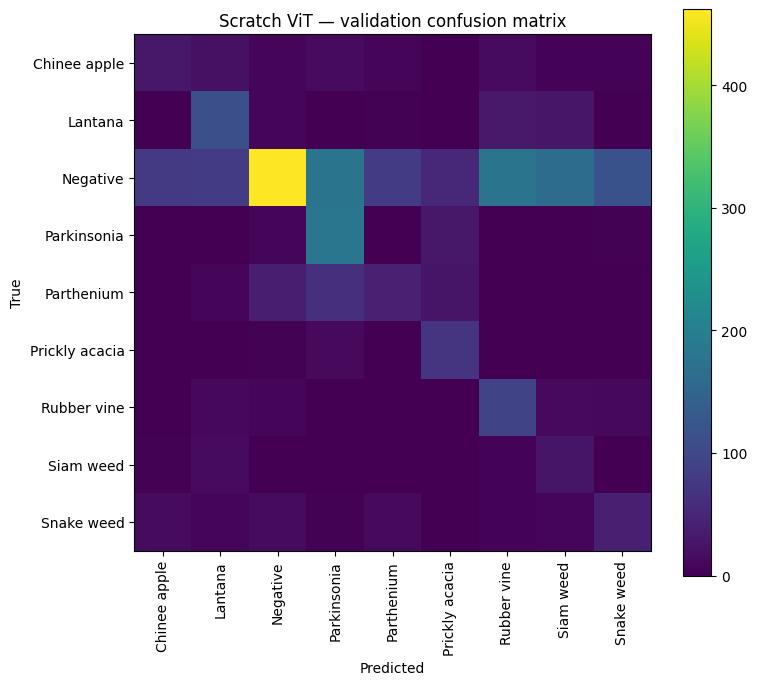

\n========================================================================
HF ViT-B/16
                precision    recall  f1-score   support

  Chinee apple     0.4804    0.8350    0.6099       103
       Lantana     0.8900    0.9674    0.9271       184
      Negative     0.9481    0.7875    0.8604      1393
   Parkinsonia     0.7336    0.9550    0.8297       222
    Parthenium     0.8968    0.6384    0.7459       177
Prickly acacia     0.3925    0.9655    0.5581        87
   Rubber vine     0.9417    0.8370    0.8863       135
     Siam weed     0.5375    0.8776    0.6667        49
    Snake weed     0.8315    0.7115    0.7668       104

      accuracy                         0.8150      2454
     macro avg     0.7391    0.8417    0.7612      2454
  weighted avg     0.8678    0.8150    0.8267      2454



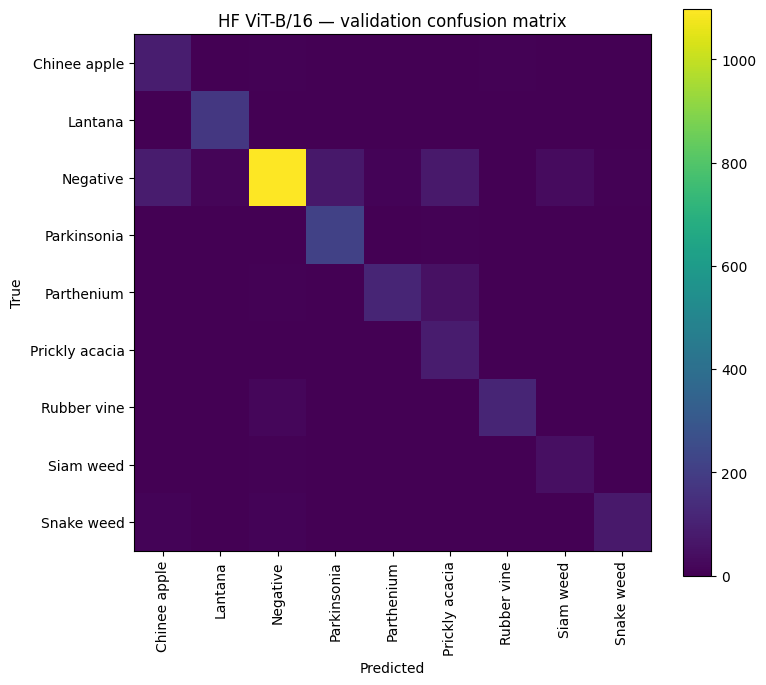

In [23]:
criterion = nn.CrossEntropyLoss()
scratch_eval = evaluate_model(scratch_model, val_loader, criterion)
hf_eval = evaluate_model(hf_classifier, val_loader, criterion)

for name, result in [("Scratch ViT", scratch_eval), ("HF ViT-B/16", hf_eval)]:
    print("\\n" + "=" * 72)
    print(name)
    print(classification_report(result["y_true"], result["y_pred"],
                                labels=list(range(NUM_CLASSES)), target_names=classes,
                                digits=4, zero_division=0))
    cm = confusion_matrix(result["y_true"], result["y_pred"], labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{name} — validation confusion matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks(range(NUM_CLASSES), classes, rotation=90)
    ax.set_yticks(range(NUM_CLASSES), classes)
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()
